In [37]:
print("Welcome to IPL Win Probability Prediction!")
print("Our first Machine Learning project starts here.")

Welcome to IPL Win Probability Prediction!
Our first Machine Learning project starts here.


In [38]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import json
import zipfile

print("Python environment is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Python environment is ready!
Pandas version: 2.2.3
NumPy version: 2.4.6
Scikit-learn version: 1.6.1


In [39]:

import urllib.request

url = "https://cricsheet.org/downloads/ipl_male_json.zip"

zip_path = "/content/ipl_male_json.zip"

urllib.request.urlretrieve(url, zip_path)

print("IPL dataset downloaded successfully!")
print("File location:", zip_path)


IPL dataset downloaded successfully!
File location: /content/ipl_male_json.zip


In [40]:

import os

file_size = os.path.getsize(zip_path)

print("Dataset exists:", os.path.exists(zip_path))
print("Dataset size:", round(file_size / (1024 * 1024), 2), "MB")


Dataset exists: True
Dataset size: 4.97 MB


In [41]:

import zipfile
import os

extract_path = "/content/ipl_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Folder location:", extract_path)


Dataset extracted successfully!
Folder location: /content/ipl_data


In [42]:

json_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".json"):
            json_files.append(os.path.join(root, file))

print("Total JSON match files:", len(json_files))
print("\nFirst 10 match files:")

for file in json_files[:10]:
    print(os.path.basename(file))


Total JSON match files: 1243

First 10 match files:
419153.json
548377.json
392227.json
501269.json
734031.json
392229.json
392198.json
501239.json
1426311.json
1473448.json


In [43]:

import json

with open(json_files[0], "r") as f:
    match_data = json.load(f)

print("Match information:")
print(json.dumps(match_data["info"], indent=4)[:3000])


Match information:
{
    "balls_per_over": 6,
    "city": "Chennai",
    "dates": [
        "2010-04-13"
    ],
    "event": {
        "match_number": 48,
        "name": "Indian Premier League"
    },
    "gender": "male",
    "match_type": "T20",
    "officials": {
        "match_referees": [
            "GR Viswanath"
        ],
        "reserve_umpires": [
            "J Madanagopal"
        ],
        "tv_umpires": [
            "HDPK Dharmasena"
        ],
        "umpires": [
            "SS Hazare",
            "SJA Taufel"
        ]
    },
    "outcome": {
        "by": {
            "wickets": 9
        },
        "winner": "Chennai Super Kings"
    },
    "overs": 20,
    "player_of_match": [
        "R Ashwin"
    ],
    "players": {
        "Chennai Super Kings": [
            "M Vijay",
            "ML Hayden",
            "SK Raina",
            "S Anirudha",
            "MS Dhoni",
            "S Badrinath",
            "JA Morkel",
            "R Ashwin",
            "

In [44]:
print("Innings available:")

for i, innings in enumerate(match_data["innings"]):
    print("\nInnings number:", i + 1)
    print("Batting team:", innings["team"])
    print("Number of overs:", len(innings["overs"]))

    print("First over data:")
    print(innings["overs"][0])

Innings available:

Innings number: 1
Batting team: Kolkata Knight Riders
Number of overs: 20
First over data:
{'over': 0, 'deliveries': [{'actual_delivery': '0.1', 'batter': 'SC Ganguly', 'bowler': 'R Ashwin', 'non_striker': 'CH Gayle', 'runs': {'batter': 0, 'extras': 0, 'total': 0}}, {'actual_delivery': '0.2', 'batter': 'SC Ganguly', 'bowler': 'R Ashwin', 'non_striker': 'CH Gayle', 'runs': {'batter': 0, 'extras': 0, 'total': 0}}, {'actual_delivery': '0.3', 'batter': 'SC Ganguly', 'bowler': 'R Ashwin', 'non_striker': 'CH Gayle', 'runs': {'batter': 1, 'extras': 0, 'total': 1}}, {'actual_delivery': '0.4', 'batter': 'CH Gayle', 'bowler': 'R Ashwin', 'non_striker': 'SC Ganguly', 'runs': {'batter': 1, 'extras': 0, 'total': 1}}, {'actual_delivery': '0.5', 'batter': 'SC Ganguly', 'bowler': 'R Ashwin', 'non_striker': 'CH Gayle', 'runs': {'batter': 1, 'extras': 0, 'total': 1}}, {'actual_delivery': '0.6', 'batter': 'CH Gayle', 'bowler': 'R Ashwin', 'non_striker': 'SC Ganguly', 'runs': {'batter'

In [45]:
second_innings = match_data["innings"][1]

total_runs = 0
total_wickets = 0

for over in second_innings["overs"]:
    for delivery in over["deliveries"]:

        total_runs += delivery["runs"]["total"]

        if "wickets" in delivery:
            total_wickets += len(delivery["wickets"])

print("Batting team:", second_innings["team"])
print("Total runs:", total_runs)
print("Total wickets lost:", total_wickets)

Batting team: Chennai Super Kings
Total runs: 143
Total wickets lost: 1


In [46]:
runs_after_10 = 0
wickets_after_10 = 0

for over in second_innings["overs"]:
    if over["over"] >= 10:
        break

    for delivery in over["deliveries"]:
        runs_after_10 += delivery["runs"]["total"]

        if "wickets" in delivery:
            wickets_after_10 += len(delivery["wickets"])

print("Score after 10 overs:",
      runs_after_10, "/", wickets_after_10)

Score after 10 overs: 103 / 1


In [47]:
last_3_overs_runs = 0

for over in second_innings["overs"]:
    if over["over"] in [7, 8, 9]:
        for delivery in over["deliveries"]:
            last_3_overs_runs += delivery["runs"]["total"]

print("Runs in overs 8, 9 and 10:",
      last_3_overs_runs)

Runs in overs 8, 9 and 10: 27


In [48]:
seasons = []

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    season = data["info"].get("season")

    if season is not None:
        seasons.append(str(season))

unique_seasons = sorted(set(seasons))

print("Total seasons:", len(unique_seasons))
print("\nAvailable IPL seasons:")

for season in unique_seasons:
    print(season)

Total seasons: 19

Available IPL seasons:
2007/08
2009
2009/10
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020/21
2021
2022
2023
2024
2025
2026


In [49]:
from collections import Counter

season_counts = Counter(seasons)

print("Matches available per season:\n")

for season in unique_seasons:
    print(season, ":", season_counts[season])

Matches available per season:

2007/08 : 58
2009 : 57
2009/10 : 60
2011 : 73
2012 : 74
2013 : 76
2014 : 60
2015 : 59
2016 : 60
2017 : 59
2018 : 60
2019 : 60
2020/21 : 60
2021 : 60
2022 : 74
2023 : 74
2024 : 71
2025 : 74
2026 : 74


In [50]:
def extract_match_features(data):

    innings = data.get("innings", [])

    if len(innings) < 2:
        return None

    second = innings[1]

    runs = 0
    wickets = 0
    last_3_runs = 0

    for over in second["overs"]:

        for delivery in over["deliveries"]:

            runs += delivery["runs"]["total"]

            if "wickets" in delivery:
                wickets += len(delivery["wickets"])

            if over["over"] in [7, 8, 9]:
                last_3_runs += delivery["runs"]["total"]

    return {
        "team": second["team"],
        "runs": runs,
        "wickets": wickets,
        "last_3_runs": last_3_runs
    }

print("Feature extraction function created!")

Feature extraction function created!


In [51]:
def extract_10_over_data(innings):

    runs = 0
    wickets = 0
    last_3_runs = 0

    for over in innings["overs"]:

        if over["over"] >= 10:
            break

        for delivery in over["deliveries"]:

            runs += delivery["runs"]["total"]

            if "wickets" in delivery:
                wickets += len(delivery["wickets"])

            if over["over"] in [7, 8, 9]:
                last_3_runs += delivery["runs"]["total"]

    return runs, wickets, last_3_runs


print("Ten-over extraction function created!")

Ten-over extraction function created!


In [52]:
score, wickets, recent_runs = extract_10_over_data(second_innings)

print("Score after 10 overs:", score)
print("Wickets lost:", wickets)
print("Wickets in hand:", 10 - wickets)
print("Runs in last 3 overs:", recent_runs)

Score after 10 overs: 103
Wickets lost: 1
Wickets in hand: 9
Runs in last 3 overs: 27


In [53]:
print("Second innings target information:")

print(second_innings.get("target", "No target information"))

print("\nMatch outcome:")

print(match_data["info"].get("outcome"))

Second innings target information:
{'overs': 20, 'runs': 140}

Match outcome:
{'by': {'wickets': 9}, 'winner': 'Chennai Super Kings'}


In [54]:
for file in json_files[:10]:

    with open(file, "r") as f:
        data = json.load(f)

    innings = data.get("innings", [])

    if len(innings) >= 2:

        print("\nFile:", os.path.basename(file))
        print("Target:", innings[1].get("target"))
        print("Outcome:", data["info"].get("outcome"))


File: 419153.json
Target: {'overs': 20, 'runs': 140}
Outcome: {'by': {'wickets': 9}, 'winner': 'Chennai Super Kings'}

File: 548377.json
Target: {'overs': 20, 'runs': 163}
Outcome: {'by': {'wickets': 10}, 'winner': 'Mumbai Indians'}

File: 392227.json
Target: {'overs': 20, 'runs': 148}
Outcome: {'by': {'wickets': 7}, 'winner': 'Chennai Super Kings'}

File: 501269.json
Target: {'overs': 20, 'runs': 148}
Outcome: {'by': {'wickets': 4}, 'winner': 'Mumbai Indians'}

File: 734031.json
Target: {'overs': 20, 'runs': 174}
Outcome: {'by': {'runs': 15}, 'winner': 'Mumbai Indians'}

File: 392229.json
Target: {'overs': 20, 'runs': 135}
Outcome: {'by': {'runs': 1}, 'winner': 'Kings XI Punjab'}

File: 392198.json
Target: {'overs': 20, 'runs': 144}
Outcome: {'by': {'wickets': 5}, 'winner': 'Rajasthan Royals'}

File: 501239.json
Target: {'overs': 20, 'runs': 170}
Outcome: {'by': {'runs': 20}, 'winner': 'Kolkata Knight Riders'}

File: 1426311.json
Target: {'overs': 20, 'runs': 176}
Outcome: {'winner':

In [55]:
import pandas as pd
import json
import os

dataset = []

skipped = 0

for file in json_files:

    with open(file, "r") as f:
        data = json.load(f)

    info = data.get("info", {})
    innings = data.get("innings", [])
    outcome = info.get("outcome", {})

    # Check standard 20-over matches
    if info.get("overs") != 20:
        skipped += 1
        continue

    # Exclude extra innings, ties and no-results
    if len(innings) != 2 or not outcome.get("winner"):
        skipped += 1
        continue

    if outcome.get("method") or outcome.get("result") in ["tie", "no result"]:
        skipped += 1
        continue

    second = innings[1]
    target_info = second.get("target", {})

    # Exclude revised or shortened targets
    if target_info.get("overs") != 20:
        skipped += 1
        continue

    target = target_info.get("runs")

    if target is None:
        skipped += 1
        continue

    # Check that the first 10 overs exist
    over_numbers = {o["over"] for o in second["overs"]}

    if not all(i in over_numbers for i in range(10)):
        skipped += 1
        continue

    # Extract ten-over information
    score, wickets, recent_runs = extract_10_over_data(second)

    # Exclude matches already decided before the snapshot
    if score >= target or wickets >= 10:
        skipped += 1
        continue

    season = str(info.get("season", ""))

    dataset.append({
        "season": season,
        "team": second["team"],
        "target": target,
        "score_10": score,
        "runs_required": target - score,
        "wickets_lost": wickets,
        "wickets_in_hand": 10 - wickets,
        "last_3_overs_runs": recent_runs,
        "result": int(outcome["winner"] == second["team"])
    })

df = pd.DataFrame(dataset)

print("Dataset created successfully!")
print("Eligible matches:", len(df))
print("Skipped matches:", skipped)

print("\nFirst 10 dataset rows:")
display(df.head(10))

print("\nDataset shape:", df.shape)

Dataset created successfully!
Eligible matches: 1173
Skipped matches: 70

First 10 dataset rows:


,season,team,target,score_10,runs_required,wickets_lost,wickets_in_hand,last_3_overs_runs,result
0,2009/10,Chennai Super Kings,140,103,37,1,9,27,1
1,2012,Mumbai Indians,163,79,84,0,10,22,1
2,2009,Chennai Super Kings,148,56,92,2,8,17,1
3,2011,Mumbai Indians,148,87,61,2,8,16,1
4,2014,Delhi Daredevils,174,62,112,3,7,8,0
5,2009,Deccan Chargers,135,65,70,2,8,16,0
6,2009,Rajasthan Royals,144,60,84,3,7,24,1
7,2011,Deccan Chargers,170,68,102,2,8,22,0
8,2024,Rajasthan Royals,176,73,103,3,7,17,0
9,2025,Chennai Super Kings,183,74,109,3,7,28,0



Dataset shape: (1173, 9)


In [56]:
def innings_stats(innings, first_10_only=False):
    legal_balls = 0
    wickets = 0

    for over in innings["overs"]:
        if first_10_only and over["over"] >= 10:
            break

        for delivery in over["deliveries"]:
            extras = delivery.get("extras", {})

            if "wides" not in extras and "noballs" not in extras:
                legal_balls += 1

            wickets += len(delivery.get("wickets", []))

    return legal_balls, wickets


dataset = []
skipped = 0

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    info = data.get("info", {})
    innings = data.get("innings", [])
    outcome = info.get("outcome", {})

    if info.get("overs") != 20:
        skipped += 1
        continue

    if len(innings) != 2 or not outcome.get("winner"):
        skipped += 1
        continue

    if info.get("method") or outcome.get("method"):
        skipped += 1
        continue

    if outcome.get("result") in ["tie", "no result"]:
        skipped += 1
        continue

    first = innings[0]
    second = innings[1]

    target_info = second.get("target", {})
    target = target_info.get("runs")

    if target is None or target_info.get("overs") != 20:
        skipped += 1
        continue

    first_balls, first_wickets = innings_stats(first)
    second_balls, _ = innings_stats(second, True)

    # First innings must reach 20 overs or be all out
    if first_balls < 120 and first_wickets < 10:
        skipped += 1
        continue

    # Second innings must complete 10 overs
    if second_balls < 60:
        skipped += 1
        continue

    score, wickets, recent_runs = extract_10_over_data(second)

    # Chase must still be in progress after 10 overs
    if score >= target or wickets >= 10:
        skipped += 1
        continue

    dataset.append({
        "season": str(info.get("season", "")),
        "team": second["team"],
        "target": target,
        "score_10": score,
        "runs_required": target - score,
        "wickets_lost": wickets,
        "wickets_in_hand": 10 - wickets,
        "last_3_overs_runs": recent_runs,
        "result": int(outcome["winner"] == second["team"])
    })

df = pd.DataFrame(dataset)

print("Strictly filtered dataset created!")
print("Eligible matches:", len(df))
print("Skipped matches:", skipped)
print("Dataset shape:", df.shape)

display(df.head(10))

Strictly filtered dataset created!
Eligible matches: 1171
Skipped matches: 72
Dataset shape: (1171, 9)


,season,team,target,score_10,runs_required,wickets_lost,wickets_in_hand,last_3_overs_runs,result
0,2009/10,Chennai Super Kings,140,103,37,1,9,27,1
1,2012,Mumbai Indians,163,79,84,0,10,22,1
2,2009,Chennai Super Kings,148,56,92,2,8,17,1
3,2011,Mumbai Indians,148,87,61,2,8,16,1
4,2014,Delhi Daredevils,174,62,112,3,7,8,0
5,2009,Deccan Chargers,135,65,70,2,8,16,0
6,2009,Rajasthan Royals,144,60,84,3,7,24,1
7,2011,Deccan Chargers,170,68,102,2,8,22,0
8,2024,Rajasthan Royals,176,73,103,3,7,17,0
9,2025,Chennai Super Kings,183,74,109,3,7,28,0


In [57]:
test_seasons = ["2025", "2026"]

train_df = df[~df["season"].isin(test_seasons)].copy()
test_df = df[df["season"].isin(test_seasons)].copy()

print("Training matches:", len(train_df))
print("Testing matches:", len(test_df))

print("\nTraining seasons:")
print(sorted(train_df["season"].unique()))

print("\nTesting seasons:")
print(sorted(test_df["season"].unique()))

print("\nTraining result distribution:")
print(train_df["result"].value_counts())

print("\nTesting result distribution:")
print(test_df["result"].value_counts())

Training matches: 1035
Testing matches: 136

Training seasons:
['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022', '2023', '2024']

Testing seasons:
['2025', '2026']

Training result distribution:
result
1    555
0    480
Name: count, dtype: int64

Testing result distribution:
result
1    78
0    58
Name: count, dtype: int64


In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

# Input features
X1_train = train_df[["runs_required"]]
X1_test = test_df[["runs_required"]]

X3_train = train_df[
    ["runs_required", "wickets_in_hand", "last_3_overs_runs"]
]
X3_test = test_df[
    ["runs_required", "wickets_in_hand", "last_3_overs_runs"]
]

y_train = train_df["result"]
y_test = test_df["result"]

# Model 1: Logistic Regression (one feature)
model1 = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)
model1.fit(X1_train, y_train)

# Model 2: Logistic Regression (three features)
model2 = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)
model2.fit(X3_train, y_train)

# Model 3: Shallow Decision Tree
model3 = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)
model3.fit(X3_train, y_train)

# Predictions
p1 = model1.predict_proba(X1_test)[:, 1]
p2 = model2.predict_proba(X3_test)[:, 1]
p3 = model3.predict_proba(X3_test)[:, 1]

# Compare ROC-AUC
print("MODEL COMPARISON")
print("-------------------------")
print("Logistic Regression (1 feature):",
      round(roc_auc_score(y_test, p1), 3))

print("Logistic Regression (3 features):",
      round(roc_auc_score(y_test, p2), 3))

print("Decision Tree (3 features):",
      round(roc_auc_score(y_test, p3), 3))

MODEL COMPARISON
-------------------------
Logistic Regression (1 feature): 0.915
Logistic Regression (3 features): 0.921
Decision Tree (3 features): 0.886


In [59]:
probability_df = pd.DataFrame({
    "Actual_Result": y_test.values,
    "Predicted_Probability": p2
})

probability_df["Probability_Band"] = pd.cut(
    probability_df["Predicted_Probability"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    include_lowest=True
)

print(probability_df.head(10))

   Actual_Result  Predicted_Probability Probability_Band
0              0               0.242101       (0.2, 0.4]
1              1               0.353964       (0.2, 0.4]
2              1               0.783088       (0.6, 0.8]
3              0               0.167678    (-0.001, 0.2]
4              0               0.117203    (-0.001, 0.2]
5              1               0.851311       (0.8, 1.0]
6              0               0.136402    (-0.001, 0.2]
7              1               0.852564       (0.8, 1.0]
8              1               0.995479       (0.8, 1.0]
9              1               0.844899       (0.8, 1.0]


In [60]:
calibration = probability_df.groupby(
    "Probability_Band",
    observed=False
).agg(
    Match_Count=("Actual_Result", "count"),
    Mean_Predicted=("Predicted_Probability", "mean"),
    Actual_Win_Rate=("Actual_Result", "mean")
)

print(calibration.round(3))

                  Match_Count  Mean_Predicted  Actual_Win_Rate
Probability_Band                                              
(-0.001, 0.2]              42           0.066            0.071
(0.2, 0.4]                 26           0.292            0.500
(0.4, 0.6]                 14           0.507            0.786
(0.6, 0.8]                 23           0.702            0.913
(0.8, 1.0]                 31           0.881            0.968


In [61]:
# Find a typical value for runs in the previous 3 overs
fixed_recent_runs = train_df["last_3_overs_runs"].median()

# Create the three required scenarios
scenarios = pd.DataFrame({
    "runs_required": [85, 85, 85],
    "wickets_in_hand": [9, 7, 5],
    "last_3_overs_runs": [fixed_recent_runs] * 3
})

# Predict win probabilities
scenarios["Win_Probability"] = model2.predict_proba(scenarios)[:, 1]

# Convert probabilities into percentages
scenarios["Win_Probability_Percent"] = (
    scenarios["Win_Probability"] * 100
).round(2)

print("Fixed previous 3 overs runs:", fixed_recent_runs)
print(scenarios)

Fixed previous 3 overs runs: 22.0
   runs_required  wickets_in_hand  last_3_overs_runs  Win_Probability  \
0             85                9               22.0         0.771884   
1             85                7               22.0         0.563880   
2             85                5               22.0         0.330674   

   Win_Probability_Percent  
0                    77.19  
1                    56.39  
2                    33.07  


In [62]:
for wickets_lost in [1, 3, 5]:

    similar = df[
        (df["target"].between(165, 175)) &
        (df["score_10"].between(80, 90)) &
        (df["wickets_lost"] == wickets_lost) &
        (df["last_3_overs_runs"].between(17, 27))
    ]

    print(f"\nSituation: 85/{wickets_lost}")
    print("Similar matches:", len(similar))

    if len(similar) > 0:
        print("Actual wins:", similar["result"].sum())
        print("Actual win rate:",
              round(similar["result"].mean() * 100, 2), "%")


Situation: 85/1
Similar matches: 13
Actual wins: 11
Actual win rate: 84.62 %

Situation: 85/3
Similar matches: 6
Actual wins: 4
Actual win rate: 66.67 %

Situation: 85/5
Similar matches: 2
Actual wins: 0
Actual win rate: 0.0 %


In [63]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression (1 Feature)",
        "Logistic Regression (3 Features)",
        "Decision Tree (3 Features)"
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, p1),
        roc_auc_score(y_test, p2),
        roc_auc_score(y_test, p3)
    ]
})

print(model_results.round(3))

                              Model  ROC_AUC
0   Logistic Regression (1 Feature)    0.915
1  Logistic Regression (3 Features)    0.921
2        Decision Tree (3 Features)    0.886


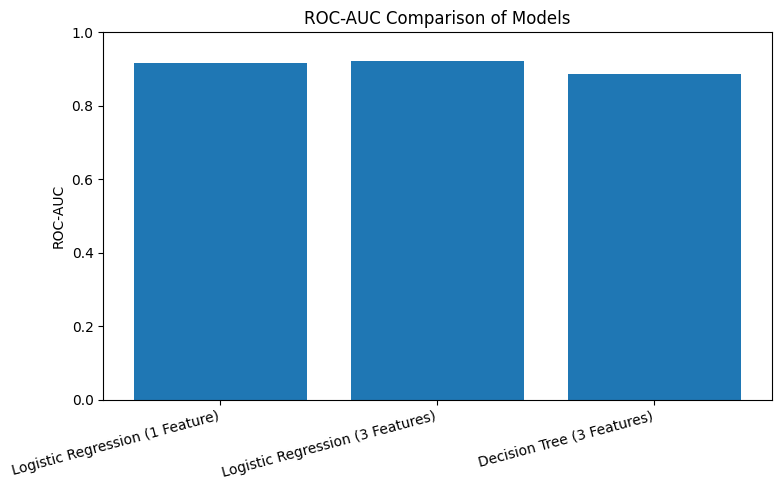

In [64]:
import matplotlib.pyplot as plt

# Graph 1: Model comparison
plt.figure(figsize=(8, 5))
plt.bar(model_results["Model"], model_results["ROC_AUC"])
plt.title("ROC-AUC Comparison of Models")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

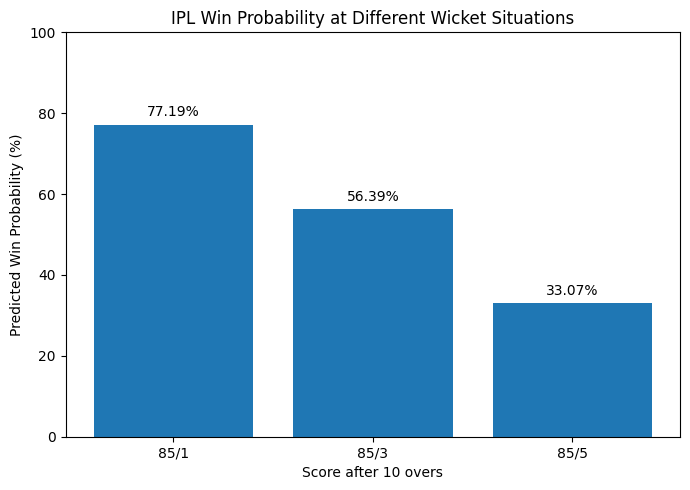

In [65]:
plt.figure(figsize=(7, 5))

situations = ["85/1", "85/3", "85/5"]
probabilities = scenarios["Win_Probability_Percent"]

plt.bar(situations, probabilities)

plt.title("IPL Win Probability at Different Wicket Situations")
plt.xlabel("Score after 10 overs")
plt.ylabel("Predicted Win Probability (%)")
plt.ylim(0, 100)

for i, value in enumerate(probabilities):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

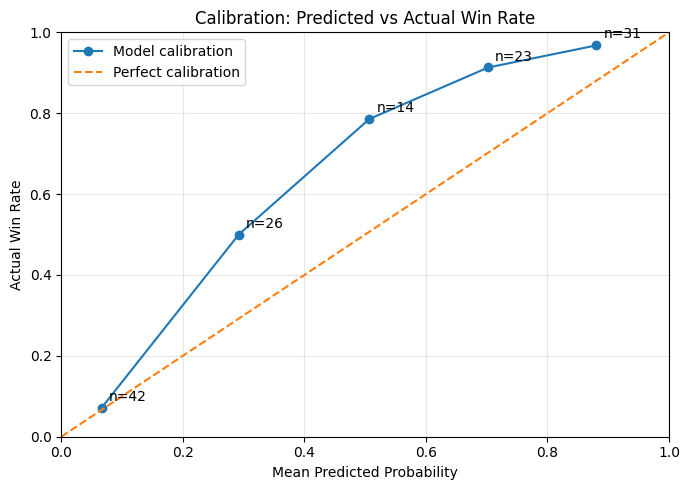

In [66]:
plt.figure(figsize=(7, 5))

plt.plot(
    calibration["Mean_Predicted"],
    calibration["Actual_Win_Rate"],
    marker="o",
    label="Model calibration"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

for index, row in calibration.iterrows():
    plt.annotate(
        f"n={int(row['Match_Count'])}",
        (row["Mean_Predicted"], row["Actual_Win_Rate"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Calibration: Predicted vs Actual Win Rate")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Win Rate")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()